In [1]:
# ---------------------------------------------------------------------------
# 0. Import Libraries and Reproducibility setup
# ---------------------------------------------------------------------------
import os
import sys
import numpy
import scipy
import matplotlib
import sklearn
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel, WhiteKernel
from scipy import stats
from scipy.stats import norm,spearmanr, skew
from scipy.optimize import minimize

SEED = 42                                                 # Random seed 
rng = np.random.default_rng(SEED)

print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()


# ---------------------------------------------------------------- 
# Figures setup
# ---------------------------------------------------------------- 
SURFACE, INK, INK2, MUTED, GRIDC = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e6e5e1"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": INK, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRIDC, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



In [2]:
# ---------------------------------------------------------------------------
# 1. Load data
# ---------------------------------------------------------------------------
X = np.load('..\Function_2_Data\Week_13_Data/F2_Week_13_inputs.npy')
y = np.load('..\Function_2_Data\Week_13_Data/F2_Week_13_outputs.npy')

n, d = X.shape
N_INITIAL = 10
NEW = n - 1                       # row 21: the week-12 query

obs = int(np.argmax(y))
BEST = y[obs]
print(f"n = {n} ({N_INITIAL} initial + {n - N_INITIAL} queried); newest point x = {X[NEW]}, y = {y[NEW]:.6f}")
print(f"best observed: row {obs}, x = {X[obs]}, y = {BEST:.6f}  (the newest point ranks {int((y > y[NEW]).sum()) + 1} of {n})")


n = 22 (10 initial + 12 queried); newest point x = [0.700027 0.      ], y = 0.515185
best observed: row 17, x = [0.704881 0.      ], y = 0.695096  (the newest point ranks 10 of 22)


raw y: mean 0.3939, std 0.2421, skew -0.614, range [-0.0656, 0.6951]
Standardized y: mean=-0.0000, std=1.0000


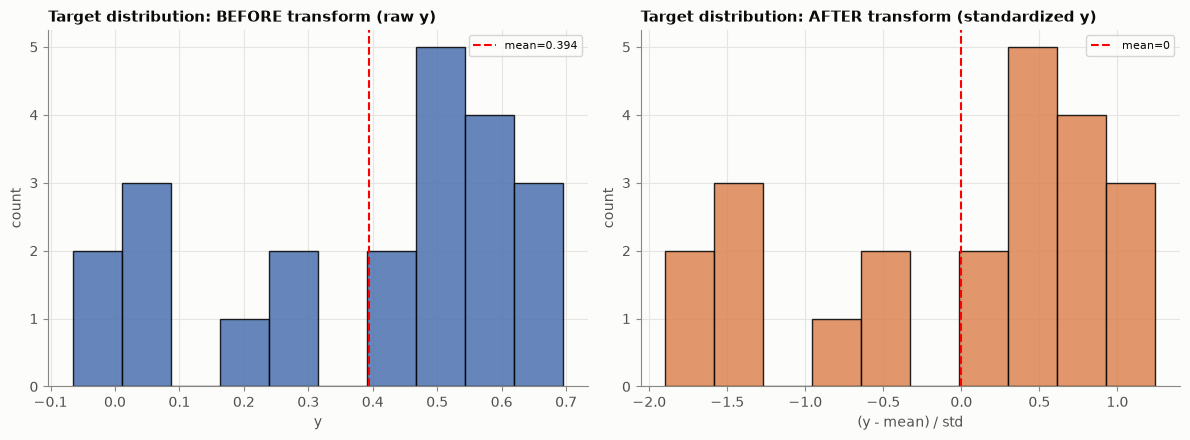

In [3]:
# ---------------------------------------------------------------------------
# 2a. Input transformation (unchanged)
# ---------------------------------------------------------------------------
# Inputs already live in [0,1] x [0,1] -- no rescaling needed.
bounds = np.array([[0.0, 1.0], [0.0, 1.0]])

# ---------------------------------------------------------------------------
# 2b. Output transformation: standardize y, with before/after plot
# ---------------------------------------------------------------------------
y_mean, y_std = y.mean(), y.std()
yt = (y - y_mean) / y_std      # t = (y - y_mean) / y_std
fig_dist, axes_dist = plt.subplots(1, 2, figsize=(12, 4.5))

axes_dist[0].hist(y, bins=10, color="#4C72B0", edgecolor="black", alpha=0.85)
axes_dist[0].axvline(y_mean, color="red", linestyle="--", linewidth=1.5, label=f"mean={y_mean:.3f}")
axes_dist[0].set_title("Target distribution: BEFORE transform (raw y)")
axes_dist[0].set_xlabel("y"); axes_dist[0].set_ylabel("count")
axes_dist[0].legend(fontsize=8)

axes_dist[1].hist(yt, bins=10, color="#DD8452", edgecolor="black", alpha=0.85)
axes_dist[1].axvline(0.0, color="red", linestyle="--", linewidth=1.5, label="mean=0")
axes_dist[1].set_title("Target distribution: AFTER transform (standardized y)")
axes_dist[1].set_xlabel("(y - mean) / std"); axes_dist[1].set_ylabel("count")
axes_dist[1].legend(fontsize=8)
plt.tight_layout()

print(f"raw y: mean {y_mean:.4f}, std {y_std:.4f}, skew {skew(y):.3f}, range [{y.min():.4f}, {y.max():.4f}]")
print(f"Standardized y: mean={yt.mean():.4f}, std={yt.std():.4f}")

c:\Users\Ilias\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 1.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\Ilias\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 10.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\Ilias\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 10.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(



KERNEL COMPARISON (standardised y; LOO with hyperparameters fixed at the full fit)
  ARD Matern 5/2, bounds 0.05-1 (week-10)        ls=[0.0621 1.    ] noise sd=0.0679 LML=-19.85 LOO RMSE/std=0.637 Spearman=0.697 mean log pred density=-0.659
  ARD Matern 5/2, bounds 0.05-10 (recommended)   ls=[ 0.0815 10.    ] noise sd=0.0661 LML=-17.37 LOO RMSE/std=0.595 Spearman=0.749 mean log pred density=-0.519
  ARD Matern 3/2, bounds 0.05-10                 ls=[ 0.0917 10.    ] noise sd=0.0654 LML=-17.68 LOO RMSE/std=0.610 Spearman=0.753 mean log pred density=-0.554
  Isotropic Matern 5/2, bounds 0.05-10           ls=[0.1078] noise sd=0.0769 LML=-25.22 LOO RMSE/std=0.776 Spearman=0.674 mean log pred density=-0.974

Likelihood weights for the kernel average: ARD Matern 5/2: 0.0461, ARD Matern 5/2: 0.5501, ARD Matern 3/2: 0.4036, Isotropic Matern 5/2: 0.0002


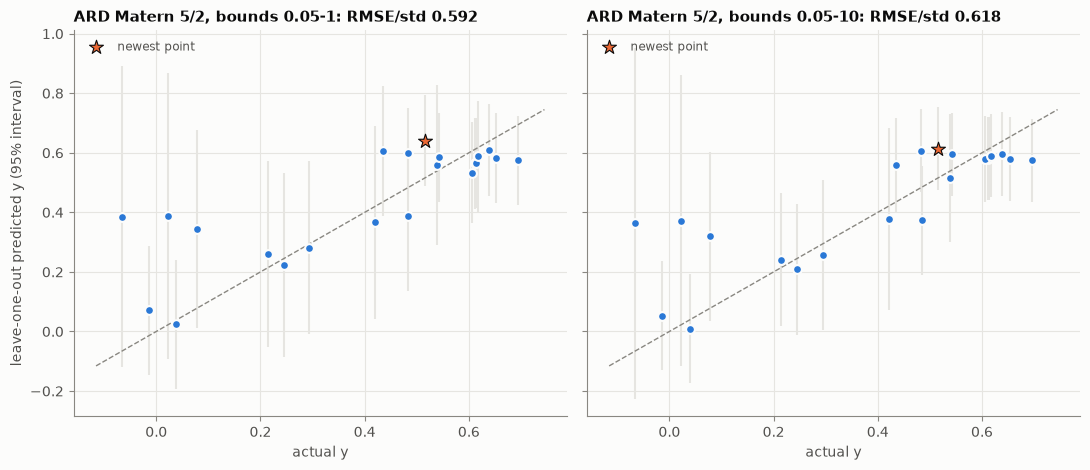

In [4]:
# ---------------------------------------------------------------- 
# kernel variants
# ----------------------------------------------------------------

def make_kernel(ls0, bounds, nu):
    return (ConstantKernel(1.0, (1e-3, 1e3)) * Matern(length_scale=ls0, length_scale_bounds=bounds, nu=nu)
            + WhiteKernel(1e-3, (1e-8, 2e-1)))

def fit(Xf, yt, ls0, bounds, nu=2.5):
    return GaussianProcessRegressor(kernel=make_kernel(ls0, bounds, nu), n_restarts_optimizer=20,
                                    random_state=SEED).fit(Xf, yt)

def loo(gp):
    mu, sd = np.empty(n), np.empty(n)
    for i in range(n):
        keep = np.arange(n) != i
        g = GaussianProcessRegressor(kernel=gp.kernel_, optimizer=None).fit(X[keep], yt[keep])
        a, b = g.predict(X[i:i + 1], return_std=True)
        mu[i], sd[i] = a[0], b[0]
    return mu, sd

SPECS = {
    "ARD Matern 5/2, bounds 0.05-1 (week-10)": ([0.3, 0.3], (0.05, 1.0), 2.5),
    "ARD Matern 5/2, bounds 0.05-10 (recommended)": ([0.3, 0.3], (0.05, 10.0), 2.5),
    "ARD Matern 3/2, bounds 0.05-10": ([0.3, 0.3], (0.05, 10.0), 1.5),
    "Isotropic Matern 5/2, bounds 0.05-10": (0.3, (0.05, 10.0), 2.5),
}
variants = {k: fit(X, yt, *v) for k, v in SPECS.items()}
CURRENT, REC = list(variants)[0], list(variants)[1]
loos = {}
print("\nKERNEL COMPARISON (standardised y; LOO with hyperparameters fixed at the full fit)")
for name, gp_ in variants.items():
    mu, sd = loo(gp_)
    loos[name] = (mu, sd)
    ls = np.atleast_1d(gp_.kernel_.k1.k2.length_scale)
    print(f"  {name:46s} ls={np.round(ls, 4)} noise sd={np.sqrt(gp_.kernel_.k2.noise_level) * y_std:.4f} "
          f"LML={gp_.log_marginal_likelihood_value_:.2f} LOO RMSE/std={np.sqrt(np.mean((yt - mu) ** 2)):.3f} "
          f"Spearman={spearmanr(yt, mu)[0]:.3f} mean log pred density={np.mean(norm.logpdf(yt, mu, sd)):.3f}")
gp = variants[REC]
noise_sd_raw = np.sqrt(gp.kernel_.k2.noise_level) * y_std

lml = np.array([g_.log_marginal_likelihood_value_ for g_ in variants.values()])
weights = np.exp(lml - lml.max()); weights /= weights.sum()
W = dict(zip(variants, weights))
print("\nLikelihood weights for the kernel average: " + ", ".join(f"{k.split(',')[0]}: {v:.4f}" for k, v in W.items()))

def pred_raw(Z, model):
    """Predictive mean and sd of a NEW OBSERVATION (latent + noise), raw y units."""
    m, s = model.predict(np.atleast_2d(Z), return_std=True)
    return m * y_std + y_mean, s * y_std

def ei_best(Z, model):
    """Expected improvement of one new observation over the best observed value."""
    m, s = pred_raw(Z, model)
    z = (m - BEST) / s
    return (m - BEST) * norm.cdf(z) + s * norm.pdf(z)

def p_best(Z, model):
    m, s = pred_raw(Z, model)
    return norm.sf((BEST - m) / s)

def ei_avg(Z):
    return sum(W[k] * ei_best(Z, g_) for k, g_ in variants.items())

def p_avg(Z):
    return sum(W[k] * p_best(Z, g_) for k, g_ in variants.items())


# Fig 3: LOO for week-10 vs recommended kernel
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
for ax, name in zip(axes, [CURRENT, REC]):
    mu, sd = loos[name]
    yt, ym, ys = y, mu * y_std + y_mean, sd * y_std
    lim = [min(yt.min(), ym.min()) - 0.05, max(yt.max(), ym.max()) + 0.05]
    ax.plot(lim, lim, color=MUTED, lw=1, ls="--")
    ax.errorbar(yt, ym, yerr=1.96 * ys, fmt="none", ecolor=GRIDC, elinewidth=1.5, zorder=1)
    ax.scatter(yt, ym, s=40, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=3)
    ax.scatter(yt[NEW], ym[NEW], s=110, marker="*", color=ORANGE, edgecolor=INK, linewidth=0.8, zorder=4, label="newest point")
    ax.set_title(f"{name.split('(')[0].strip()}: RMSE/std {np.sqrt(np.mean((yt - mu) ** 2)):.3f}")
    ax.set_xlabel("actual y"); ax.legend(frameon=False, loc="upper left", labelcolor=INK2, fontsize=8.5)
axes[0].set_ylabel("leave-one-out predicted y (95% interval)")
fig.tight_layout()

c:\Users\Ilias\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 10.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(



WEEK-12 PREDICTION at [0.700027 0.      ]: mean 0.6151, latent sd 0.0256, observation sd 0.0670; observed 0.5152; error -0.1000 = -1.49 observation sd
  its nearest x2 = 0 neighbours: row 16 (x1 0.7056, y 0.653, distance 0.0055), row 17 (x1 0.7049, y 0.695, distance 0.0049), row 20 (x1 0.6964, y 0.639, distance 0.0036)


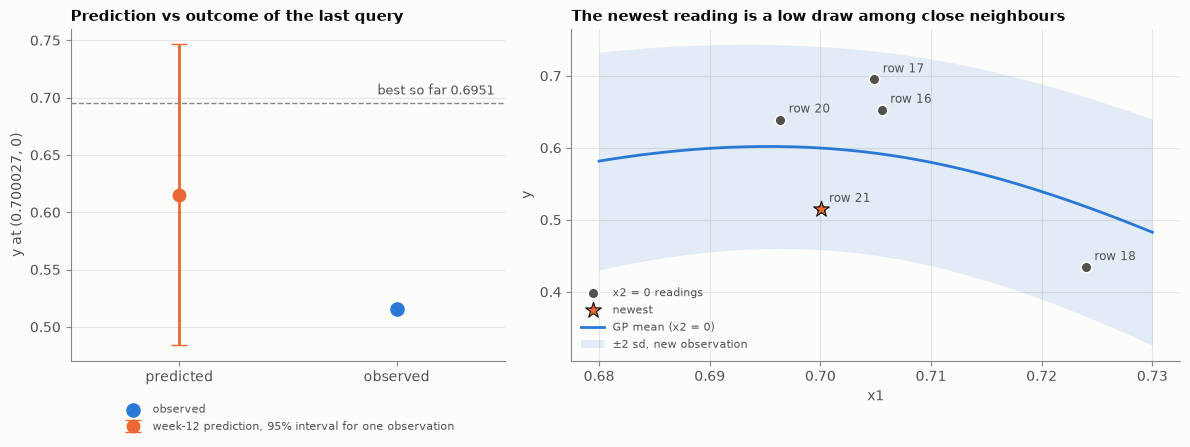

In [5]:
# ---------------------------------------------------------------- 
# Week-12 prediction check
# ---------------------------------------------------------------- 

NEWX = X[NEW]
Xp, yp = X[:NEW], y[:NEW]
tp = (yp - yp.mean()) / yp.std()
gp_prev = fit(Xp, tp, [0.3, 0.3], (0.05, 10.0))
a, b = gp_prev.predict(X[NEW:NEW + 1], return_std=True)
lat_sd = np.sqrt(max(b[0] ** 2 - gp_prev.kernel_.k2.noise_level, 1e-18)) * yp.std()
pred_mean = a[0] * yp.std() + yp.mean()
pred_obs_sd = b[0] * yp.std()
print(f"\nWEEK-12 PREDICTION at {NEWX}: mean {pred_mean:.4f}, latent sd {lat_sd:.4f}, observation sd {pred_obs_sd:.4f}; "
      f"observed {y[NEW]:.4f}; error {y[NEW] - pred_mean:+.4f} = {(y[NEW] - pred_mean) / pred_obs_sd:+.2f} observation sd")
print(f"  its nearest x2 = 0 neighbours: " + ", ".join(
    f"row {i} (x1 {X[i, 0]:.4f}, y {y[i]:.3f}, distance {abs(X[i, 0] - NEWX[0]):.4f})"
    for i in np.where(X[:, 1] == 0)[0] if i != NEW and abs(X[i, 0] - NEWX[0]) < 0.01))

# Fig 2: prediction vs outcome for the newest point, with its x2 = 0 neighbours
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1, 1.4]})
ax = axes[0]
ax.errorbar([0], [pred_mean], yerr=[1.96 * pred_obs_sd], fmt="o", color=ORANGE, capsize=6, ms=9, lw=2,
            label="week-12 prediction, 95% interval for one observation")
ax.scatter([1], [y[NEW]], s=90, color=BLUE, zorder=3, label="observed")
ax.axhline(BEST, color=MUTED, ls="--", lw=1)
ax.text(1.45, BEST + 0.005, f"best so far {BEST:.4f}", ha="right", va="bottom", fontsize=9, color=INK2)
ax.set_xlim(-0.5, 1.5); ax.set_xticks([0, 1]); ax.set_xticklabels(["predicted", "observed"])
ax.set_ylabel(f"y at ({NEWX[0]:.6f}, {NEWX[1]:.0f})")
ax.set_title("Prediction vs outcome of the last query")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), fontsize=8, labelcolor=INK2)
ax.grid(axis="x", visible=False)
ax = axes[1]
Z0 = np.where(X[:, 1] == 0)[0]
sel = Z0[(X[Z0, 0] > 0.68) & (X[Z0, 0] < 0.73)]
ax.scatter(X[sel, 0], y[sel], s=60, color=INK2, edgecolor=SURFACE, linewidth=1.2, zorder=3, label="x2 = 0 readings")
ax.scatter(X[NEW, 0], y[NEW], s=140, marker="*", color=ORANGE, edgecolor=INK, linewidth=0.8, zorder=4, label="newest")
for i in sel:
    ax.annotate(f"row {i}", (X[i, 0], y[i]), xytext=(6, 5), textcoords="offset points", fontsize=8.5, color=INK2)
xs_ = np.linspace(0.68, 0.73, 100)
m_, s_ = pred_raw(np.column_stack([xs_, np.zeros_like(xs_)]), gp)
ax.plot(xs_, m_, color=BLUE, lw=2, label="GP mean (x2 = 0)")
ax.fill_between(xs_, m_ - 2 * s_, m_ + 2 * s_, color=BLUE, alpha=0.12, lw=0, label="±2 sd, new observation")
ax.set_xlabel("x1"); ax.set_ylabel("y"); ax.set_title("The newest reading is a low draw among close neighbours")
ax.legend(frameon=False, fontsize=8, loc="lower left", labelcolor=INK2)
fig.tight_layout()

In [6]:
# ---------------------------------------------------------------- 
# Local ridge model 
# ---------------------------------------------------------------- 

R = np.where((X[:, 0] > 0.6) & (X[:, 0] < 0.8))[0]
def design(Z):
    Z = np.atleast_2d(Z)
    return np.column_stack([np.ones(len(Z)), Z[:, 0], Z[:, 0] ** 2, Z[:, 1]])
A = design(X[R]); cq = np.linalg.lstsq(A, y[R], rcond=None)[0]
res = y[R] - A @ cq; dof = len(R) - A.shape[1]; sig_loc = np.sqrt(res @ res / dof)
cov_loc = np.linalg.inv(A.T @ A)
x1_q = -cq[1] / (2 * cq[2])
rng = np.random.default_rng(0); pk = []
for _ in range(4000):
    ii = rng.integers(0, len(R), len(R))
    bb = np.linalg.lstsq(A[ii], y[R][ii], rcond=None)[0]
    if bb[2] < 0:
        pk.append(-bb[1] / (2 * bb[2]))
pk = np.array(pk)
print(f"\nLocal ridge model on {len(R)} points (0.6 < x1 < 0.8): peak x1 = {x1_q:.4f}, curvature {cq[2]:.1f}, "
      f"x2 slope {cq[3]:+.4f} per unit, residual sd {sig_loc:.4f}")
print(f"  bootstrap peak x1: median {np.median(pk):.4f}, 68% interval {np.percentile(pk, 16):.4f}-{np.percentile(pk, 84):.4f}")
H = design(np.array([[x1_q, 0.0]])); mu_loc = (H @ cq)[0]; sd_loc = sig_loc * np.sqrt(1 + (H @ cov_loc @ H.T)[0, 0])
p_loc = stats.t.sf((BEST - mu_loc) / sd_loc, dof)
print(f"  at (x1 = {x1_q:.4f}, x2 = 0): predicted observation {mu_loc:.3f} +/- {sd_loc:.3f}; P(beat {BEST:.4f}) = {p_loc:.3f}")
Z0 = np.where(X[:, 1] == 0)[0]
near0 = Z0[(X[Z0, 0] > 0.66) & (X[Z0, 0] < 0.72)]
far = np.where((X[:, 1] > 0.8) & (X[:, 0] > 0.66) & (X[:, 0] < 0.72))[0]
print(f"  ridge readings 0.66 < x1 < 0.72: x2 = 0 rows {list(near0)} mean {y[near0].mean():.4f} sd {y[near0].std(ddof=1):.4f}; "
      f"x2 > 0.8 rows {list(far)} mean {y[far].mean():.4f} sd {y[far].std(ddof=1):.4f}")


Local ridge model on 14 points (0.6 < x1 < 0.8): peak x1 = 0.6934, curvature -61.0, x2 slope -0.0202 per unit, residual sd 0.0712
  bootstrap peak x1: median 0.6932, 68% interval 0.6818-0.7028
  at (x1 = 0.6934, x2 = 0): predicted observation 0.601 +/- 0.077; P(beat 0.6951) = 0.125
  ridge readings 0.66 < x1 < 0.72: x2 = 0 rows [np.int64(16), np.int64(17), np.int64(20), np.int64(21)] mean 0.6256 sd 0.0774; x2 > 0.8 rows [np.int64(9), np.int64(11), np.int64(12), np.int64(13), np.int64(15)] mean 0.5709 sd 0.0576



CANDIDATES for the last query (observation = latent + noise; threshold = best observed 0.6951)
  A: ridge, highest GP mean                            x = (0.695320, 0.000000)
      M5/2 ARD [0.05,1]: 0.619+/-0.077 P=0.160 EI=0.0065 | M5/2 ARD [0.05,10]: 0.602+/-0.071 P=0.094 EI=0.0031 | M3/2 ARD: 0.602+/-0.071 P=0.097 EI=0.0033 | M5/2 iso: 0.612+/-0.088 P=0.173 EI=0.0081
      likelihood-weighted: P(beat) = 0.098, EI = 0.0033
  B: ridge, local-regression peak                      x = (0.693417, 0.000000)
      M5/2 ARD [0.05,1]: 0.619+/-0.078 P=0.165 EI=0.0068 | M5/2 ARD [0.05,10]: 0.601+/-0.071 P=0.094 EI=0.0031 | M3/2 ARD: 0.601+/-0.072 P=0.096 EI=0.0033 | M5/2 iso: 0.616+/-0.089 P=0.188 EI=0.0092
      likelihood-weighted: P(beat) = 0.098, EI = 0.0033
  C: average-EI maximum over the whole domain          x = (1.000000, 0.145000)
      M5/2 ARD [0.05,1]: 0.406+/-0.255 P=0.129 EI=0.0164 | M5/2 ARD [0.05,10]: 0.431+/-0.288 P=0.179 EI=0.0279 | M3/2 ARD: 0.430+/-0.281 P=0.173 EI=0.0260

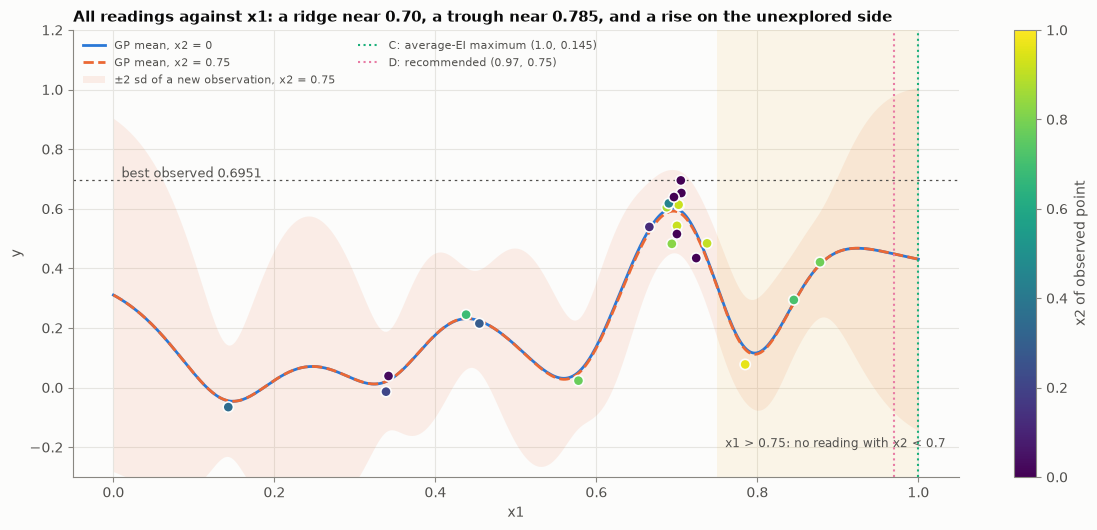

In [7]:
# ---------------------------------------------------------------- 
# Candidates
# ---------------------------------------------------------------- 

g1 = np.linspace(0, 1, 201)
G1, G2 = np.meshgrid(g1, g1)
grid = np.column_stack([G1.ravel(), G2.ravel()])

def argmax_in(fn, lo, hi):
    Z = grid[(grid[:, 0] >= lo[0]) & (grid[:, 0] <= hi[0]) & (grid[:, 1] >= lo[1]) & (grid[:, 1] <= hi[1])]
    v = fn(Z); x0 = Z[v.argmax()]
    r = minimize(lambda q: -fn(q[None])[0], x0, bounds=list(zip(lo, hi)), method="L-BFGS-B")
    return r.x if -r.fun >= v.max() else x0

x_mean_ridge = argmax_in(lambda Z: pred_raw(Z, gp)[0], (0.66, 0.0), (0.74, 0.0))
x_loc = np.array([x1_q, 0.0])
x_ei_all = argmax_in(ei_avg, (0.0, 0.0), (1.0, 1.0))
x_ei_ridge = argmax_in(ei_avg, (0.66, 0.0), (0.74, 1.0))
x_iso = argmax_in(lambda Z: ei_best(Z, variants["Isotropic Matern 5/2, bounds 0.05-10"]), (0.0, 0.0), (1.0, 1.0))
cands = {
    "A: ridge, highest GP mean": x_mean_ridge,
    "B: ridge, local-regression peak": x_loc,
    "C: average-EI maximum over the whole domain": x_ei_all,
    "D: x1 = 0.97, x2 = 0.75 (unexplored side, near the supporting readings)": np.array([0.97, 0.75]),
    "E: x1 = 0.95, x2 = 0.75 (unexplored side)": np.array([0.95, 0.75]),
    "F: isotropic-kernel EI maximum": x_iso,
}
LABEL = {"A": "A: ridge, highest GP mean", "B": "B: ridge, local-regression peak", "C": "C: average-EI maximum (1.0, 0.145)",
         "D": "D: recommended (0.97, 0.75)", "E": "E: (0.95, 0.75)", "F": "F: isotropic-kernel EI maximum"}
KN = list(variants)
SHORT = {KN[0]: "M5/2 ARD [0.05,1]", KN[1]: "M5/2 ARD [0.05,10]", KN[2]: "M3/2 ARD", KN[3]: "M5/2 iso"}
print(f"\nCANDIDATES for the last query (observation = latent + noise; threshold = best observed {BEST:.4f})")
for name, xc in cands.items():
    parts = []
    for k in KN:
        m, s = pred_raw(xc[None], variants[k])
        parts.append(f"{SHORT[k]}: {m[0]:.3f}+/-{s[0]:.3f} P={p_best(xc[None], variants[k])[0]:.3f} EI={ei_best(xc[None], variants[k])[0]:.4f}")
    print(f"  {name:52s} x = ({xc[0]:.6f}, {xc[1]:.6f})")
    print("      " + " | ".join(parts))
    print(f"      likelihood-weighted: P(beat) = {p_avg(xc[None])[0]:.3f}, EI = {ei_avg(xc[None])[0]:.4f}")
print("\n  average EI along x1 at x2 = 0.75:", {f"{v_:.2f}": round(float(ei_avg(np.array([[v_, 0.75]]))[0]), 4)
                                                 for v_ in (0.70, 0.80, 0.85, 0.90, 0.93, 0.95, 0.97, 1.00)})
print("  average P(beat) along x1 at x2 = 0.75:", {f"{v_:.2f}": round(float(p_avg(np.array([[v_, 0.75]]))[0]), 3)
                                                    for v_ in (0.70, 0.80, 0.85, 0.90, 0.93, 0.95, 0.97, 1.00)})
print("  average EI at x1 = 1.0 for x2 = 0 .. 1:", {f"{v_:.1f}": round(float(ei_avg(np.array([[1.0, v_]]))[0]), 4)
                                                    for v_ in np.linspace(0, 1, 6)})


# Fig 4: y against x1 for every reading, with the GP and the candidates
fig, ax = plt.subplots(figsize=(12, 5.4))
xs = np.linspace(0, 1, 400)
for x2v, col, ls_ in [(0.0, BLUE, "-"), (0.75, ORANGE, "--")]:
    m, s = pred_raw(np.column_stack([xs, np.full_like(xs, x2v)]), gp)
    ax.plot(xs, m, color=col, lw=2, ls=ls_, label=f"GP mean, x2 = {x2v:g}")
    if x2v == 0.75:
        ax.fill_between(xs, m - 2 * s, m + 2 * s, color=col, alpha=0.10, lw=0, label="±2 sd of a new observation, x2 = 0.75")
sc = ax.scatter(X[:, 0], y, c=X[:, 1], cmap="viridis", vmin=0, vmax=1, s=55, edgecolor=SURFACE, linewidth=1.2, zorder=4)
fig.colorbar(sc, ax=ax, label="x2 of observed point")
ax.axhline(BEST, color=INK2, lw=0.9, ls=(0, (2, 3)))
ax.text(0.01, BEST + 0.01, f"best observed {BEST:.4f}", fontsize=9, color=INK2)
ax.axvspan(0.75, 1.0, color=YELLOW, alpha=0.08, lw=0)
ax.text(0.76, -0.2, "x1 > 0.75: no reading with x2 < 0.7", fontsize=8.5, color=INK2)
for name, xc in cands.items():
    if name[0] in "CD":
        ax.axvline(xc[0], color=AQUA if name[0] == "C" else MAGENTA, lw=1.5, ls=":", label=LABEL[name[0]])
ax.set_xlabel("x1"); ax.set_ylabel("y"); ax.set_ylim(-0.3, 1.2)
ax.set_title("All readings against x1: a ridge near 0.70, a trough near 0.785, and a rise on the unexplored side")
ax.legend(frameon=False, fontsize=8, loc="upper left", labelcolor=INK2, ncol=2)
fig.tight_layout()

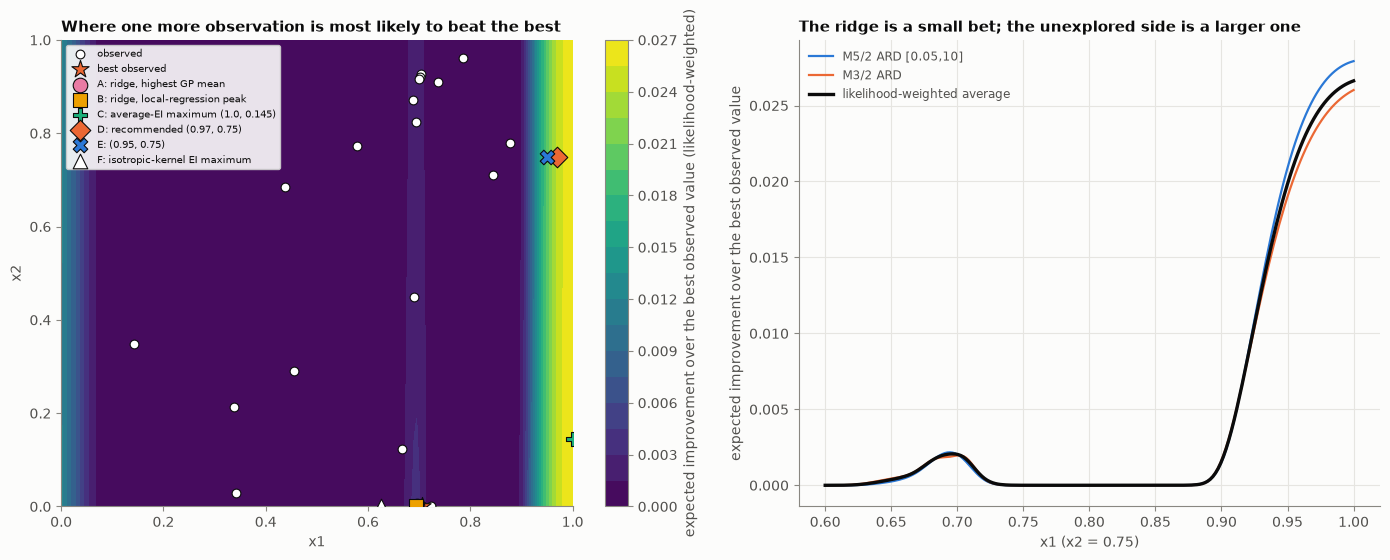

In [8]:
# Fig 5: expected improvement over the best observed value
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
E = ei_avg(grid).reshape(G1.shape)
cf = ax.contourf(G1, G2, E, levels=20, cmap="viridis")
fig.colorbar(cf, ax=ax, label="expected improvement over the best observed value (likelihood-weighted)")
ax.scatter(X[:, 0], X[:, 1], s=40, color="white", edgecolor=INK, linewidth=0.8, zorder=3, label="observed")
ax.scatter(*X[obs], s=170, marker="*", color=ORANGE, edgecolor=INK, linewidth=0.8, zorder=5, label="best observed")
marks = {"A": ("o", MAGENTA), "B": ("s", YELLOW), "C": ("P", AQUA), "D": ("D", ORANGE), "E": ("X", BLUE), "F": ("^", "white")}
for name, xc in cands.items():
    m_, c_ = marks[name[0]]
    ax.scatter(*xc, s=110, marker=m_, color=c_, edgecolor=INK, linewidth=0.8, zorder=6, label=LABEL[name[0]])
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_xlabel("x1"); ax.set_ylabel("x2")
ax.set_title("Where one more observation is most likely to beat the best")
ax.legend(frameon=True, fontsize=7, loc="upper left", framealpha=0.9); ax.grid(False)
ax = axes[1]
xs2 = np.linspace(0.60, 1.0, 200)
Zl = np.column_stack([xs2, np.full_like(xs2, 0.75)])
for k, col in zip(KN[1:3], [BLUE, ORANGE]):
    ax.plot(xs2, ei_best(Zl, variants[k]), color=col, lw=1.6, label=SHORT[k])
ax.plot(xs2, ei_avg(Zl), color=INK, lw=2.4, label="likelihood-weighted average")
ax.set_xlabel("x1 (x2 = 0.75)"); ax.set_ylabel("expected improvement over the best observed value")
ax.set_title("The ridge is a small bet; the unexplored side is a larger one")
ax.legend(frameon=False, fontsize=8.5, labelcolor=INK2)
fig.tight_layout()

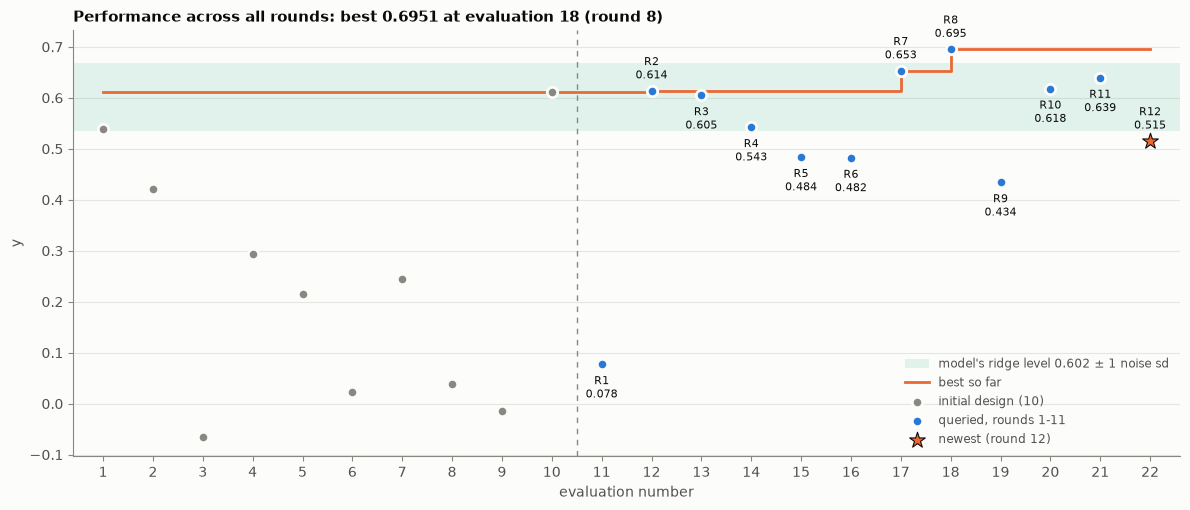

In [9]:
# Fig 1: performance across all rounds
idx = np.arange(1, n + 1)
best_sofar = np.maximum.accumulate(np.r_[np.full(N_INITIAL, y[:N_INITIAL].max()), y[N_INITIAL:]])
mu_ridge = pred_raw(x_mean_ridge[None], gp)[0][0]
fig, ax = plt.subplots(figsize=(12, 5.2))
ax.axhspan(mu_ridge - noise_sd_raw, mu_ridge + noise_sd_raw, color=AQUA, alpha=0.12, lw=0,
           label=f"model's ridge level {mu_ridge:.3f} ± 1 noise sd")
ax.axvline(N_INITIAL + 0.5, color=MUTED, lw=1, ls=(0, (4, 4)))
ax.step(idx, best_sofar, where="post", color=ORANGE, lw=2, label="best so far", zorder=2)
ax.scatter(idx[:N_INITIAL], y[:N_INITIAL], s=56, color=MUTED, edgecolor=SURFACE, linewidth=2,
           label=f"initial design ({N_INITIAL})", zorder=3)
ax.scatter(idx[N_INITIAL:NEW], y[N_INITIAL:NEW], s=56, color=BLUE, edgecolor=SURFACE, linewidth=2,
           label=f"queried, rounds 1-{n - N_INITIAL - 1}", zorder=3)
ax.scatter(idx[NEW], y[NEW], s=140, marker="*", color=ORANGE, edgecolor=INK, linewidth=0.8, zorder=4,
           label=f"newest (round {n - N_INITIAL})")
for i in range(N_INITIAL, n):
    ax.annotate(f"R{i - N_INITIAL + 1}\n{y[i]:.3f}", (idx[i], y[i]),
                xytext=(0, 9 if y[i] >= best_sofar[i] - 1e-12 or i == NEW else -24), textcoords="offset points",
                ha="center", fontsize=8, color=INK)
ax.set_xticks(idx); ax.set_xlim(0.4, n + 0.6)
ax.set_xlabel("evaluation number"); ax.set_ylabel("y")
ax.set_title(f"Performance across all rounds: best {BEST:.4f} at evaluation {obs + 1} (round {obs - N_INITIAL + 1})")
ax.legend(frameon=False, loc="lower right", fontsize=8.5, labelcolor=INK2)
ax.grid(axis="x", visible=False)
fig.tight_layout()